# 06 — High-Demand Classification

## Notebook description

This notebook trains and evaluates models that predict whether an article will meet the high-demand definition in the following week. It uses the article-week dataset and fixed target created in notebook 02, compares simple baselines with several classifier families, and interprets discrimination, calibration, decision thresholds, and errors in chronological validation.

## Objectives

- Reuse the article-week unit and leakage-safe feature policy.
- Compare simple baselines with several classifier families.
- Keep the class-definition threshold separate from the probability decision threshold.
- Evaluate discrimination, calibration, and threshold-dependent performance.
- Analyse errors and stability across time periods and product groups.
- Select a candidate classifier without using the final test set.

## Planned sections

1. Target, prevalence, and experimental setup
2. Classification baselines
3. Preprocessing pipeline
4. Candidate classifiers
5. Chronological validation metrics
6. Confusion matrix, ROC, Precision–Recall, and calibration
7. Decision-threshold and business-error analysis
8. Model selection and limitations

## Expected output

A baseline-relative classifier comparison, a documented decision-threshold policy, and an interpretation of errors in the context of inventory and commercial planning.

The notebook uses a fixed random seed and caps the training sample for practical iteration and evaluates every chronological validation row. The current saved run uses all 271,215 validation rows. The sample sizes are printed with the results. The final test partition is not used to fit, tune, select, or score a model.


## 1. Target, prevalence, and experimental setup

The positive class is `target_high_demand`. Notebook 02 defines it using next-week recorded sales greater than or equal to an integer threshold calculated from positive training targets only; this notebook reads that threshold from the current run's `summary.json` and verifies that the stored labels match it.

We retain the chronological training and validation partitions. The final test partition is kept out of the analysis. Predictors contain only information available by the end of the current week plus product metadata; target, split, identifiers, and future-week fields are explicitly excluded.


In [28]:
from hashlib import sha256
import json
from pathlib import Path
from time import perf_counter

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import ( average_precision_score, brier_score_loss, confusion_matrix, f1_score, 
                             precision_recall_curve, precision_score, recall_score, roc_auc_score, roc_curve,)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

RANDOM_STATE = 42
MAX_TRAIN_ROWS = 100_000
TARGET = "target_high_demand"
PAPER, INK, MUTED, GRID = "#FAFBFC", "#17212B", "#667085", "#DDE3EA"
BLUE, TEAL, CORAL, GOLD, VIOLET = "#2F6BFF", "#16A085", "#E76F51", "#E9A23B", "#7357C8"
MODEL_COLORS = {"Logistic regression": BLUE, "Decision tree": TEAL, "Random forest": VIOLET}

ROOT = next(
    (
        path
        for path in [Path.cwd(), *Path.cwd().parents]
        if (path / "src/data/process_data.py").is_file()
        and (path / "data/processed/CURRENT.json").is_file()
    ),
    None,
)
if ROOT is None:
    raise FileNotFoundError(
        "No CURRENT publication was found. First run "
        "`python src/data/process_data.py` from the project root."
    )

processed_dir = ROOT / "data/processed"
pointer = json.loads((processed_dir / "CURRENT.json").read_text(encoding="utf-8"))
run_dir = (processed_dir / pointer["run_dir"]).resolve()
if not run_dir.is_relative_to(processed_dir.resolve()) or pointer.get("preview"):
    raise ValueError("CURRENT.json does not point to a valid complete publication.")

checksums = json.loads((run_dir / "checksums.json").read_text(encoding="utf-8"))
dataset_path = run_dir / "article_week.csv.gz"
digest = sha256()
with dataset_path.open("rb") as stream:
    for block in iter(lambda: stream.read(4 * 1024 * 1024), b""):
        digest.update(block)
if checksums.get(dataset_path.name) != digest.hexdigest():
    raise ValueError("The checksum of article_week.csv.gz does not match checksums.json.")

summary = json.loads((run_dir / "summary.json").read_text(encoding="utf-8"))
classification_definition = summary.get("classification_target")
if not classification_definition or "threshold_units" not in classification_definition:
    raise ValueError("summary.json does not define the classification target.")
HIGH_DEMAND_THRESHOLD = int(classification_definition["threshold_units"])

NUMERIC_FEATURES = [
    "sales", "lag_1_sales", "lag_2_sales", "lag_4_sales", "lag_12_sales",
    "rolling_4w_sales_mean", "rolling_4w_sales_std", "rolling_4w_active_weeks",
    "rolling_12w_sales_mean", "rolling_12w_sales_std", "rolling_12w_active_weeks",
    "sales_trend_4w", "mean_price", "rolling_4w_mean_price",
    "price_change_from_4w_mean", "rolling_4w_online_share", "week_sin", "week_cos",
]
CATEGORICAL_FEATURES = [
    "product_type_name", "product_group_name", "index_group_name",
    "section_name", "garment_group_name", "colour_group_name",
]
FEATURES = NUMERIC_FEATURES + CATEGORICAL_FEATURES
derived_features = {"week_sin", "week_cos"}
source_columns = (set(FEATURES) - derived_features) | {
    TARGET, "target_next_week_sales", "split", "target_week", "iso_week"
}
model_data_parts = []
for data_chunk in pd.read_csv(
    dataset_path,
    usecols=sorted(source_columns),
    parse_dates=["target_week"],
    chunksize=500_000,
):
    development_chunk = data_chunk.loc[
        data_chunk["split"].isin(["train", "validation"])
    ]
    if not development_chunk.empty:
        model_data_parts.append(development_chunk)
if not model_data_parts:
    raise ValueError("The publication contains no development rows.")
model_data = pd.concat(model_data_parts, ignore_index=True)
missing_columns = sorted(source_columns - set(model_data.columns))
if missing_columns:
    raise ValueError(f"Required columns are missing from the publication: {missing_columns}")

expected_target = (
    model_data["target_next_week_sales"].ge(HIGH_DEMAND_THRESHOLD).astype("int8")
)
if not np.array_equal(
    model_data[TARGET].to_numpy(dtype="int8"),
    expected_target.to_numpy(dtype="int8"),
):
    raise ValueError("Train and validation labels do not match the threshold in summary.json.")
if not model_data[TARGET].isin([0, 1]).all():
    raise ValueError("Train and validation labels must contain only 0 and 1.")

model_data["week_sin"] = np.sin(2 * np.pi * (model_data["iso_week"] - 1) / 52.1775)
model_data["week_cos"] = np.cos(2 * np.pi * (model_data["iso_week"] - 1) / 52.1775)
train_all = model_data.loc[model_data["split"].eq("train")].copy()
validation_all = model_data.loc[model_data["split"].eq("validation")].copy()
if train_all.empty or validation_all.empty:
    raise ValueError("Train and validation partitions must be nonempty.")

def stratified_cap(frame, max_rows, seed):
    if len(frame) <= max_rows:
        return frame.copy()
    if frame[TARGET].value_counts().min() < 2:
        raise ValueError("There are too few rows in one or both classes for stratified sampling.")
    sampled, _ = train_test_split(
        frame,
        train_size=max_rows,
        random_state=seed,
        stratify=frame[TARGET],
    )
    return sampled

training_sample = stratified_cap(train_all, MAX_TRAIN_ROWS, RANDOM_STATE)
validation_sample = validation_all.copy()  # Evaluate every validation row; no validation subsampling.
y_train = training_sample[TARGET].astype("int8")
y_validation = validation_sample[TARGET].astype("int8")
if y_train.nunique() != 2 or y_validation.nunique() != 2:
    raise ValueError("Train and validation must each contain examples of both classes.")

plt.rcParams.update(
    {
        "font.family": ["Arial", "DejaVu Sans"],
        "font.size": 9,
        "text.color": INK,
        "axes.labelcolor": INK,
        "xtick.color": MUTED,
        "ytick.color": MUTED,
        "figure.facecolor": PAPER,
        "axes.facecolor": PAPER,
    }
)

def style_axis(axis):
    axis.set_axisbelow(True)
    axis.grid(axis="y", color=GRID, linewidth=0.7, alpha=0.8)
    for side in ("top", "right"):
        axis.spines[side].set_visible(False)
    for side in ("left", "bottom"):
        axis.spines[side].set_color(GRID)

def add_source(fig, text):
    fig.text(0.01, 0.012, text, ha="left", va="bottom", fontsize=8, color=MUTED)

def classification_metrics(y_true, probability, threshold=0.5):
    y_true = np.asarray(y_true, dtype=int)
    probability = np.asarray(probability, dtype=float)
    predicted = probability >= threshold
    return {
        "precision": precision_score(y_true, predicted, zero_division=0),
        "recall": recall_score(y_true, predicted, zero_division=0),
        "F1": f1_score(y_true, predicted, zero_division=0),
        "PR-AUC": average_precision_score(y_true, probability),
        "ROC-AUC": roc_auc_score(y_true, probability) if np.unique(y_true).size == 2 else np.nan,
        "Brier": brier_score_loss(y_true, probability),
    }

print("Run:", run_dir.name)
print("High-demand threshold:", HIGH_DEMAND_THRESHOLD, "recorded sales units")
print(f"Train: {len(train_all):,} rows; sample used: {len(training_sample):,}")
print(f"Validation: {len(validation_all):,} rows; sample used: {len(validation_sample):,}")
print("The test partition was excluded from modelling and was not used.")


Run: 20261027T145552-5a1ac59a
High-demand threshold: 16 recorded sales units
Train: 1,326,434 rows; sample used: 100,000
Validation: 271,215 rows; sample used: 271,215
The test partition was excluded from modelling and was not used.


,rows,high_demand_prevalence,first_target_week,last_target_week
train,1326434,19.9%,2018-12-24,2020-02-24
validation,271215,21.3%,2020-03-02,2020-06-08


,rows
partition,
train,1326434
validation,271215


Definition from notebook 02: next-week recorded sales >= 16; reference training quantile: 0.75.


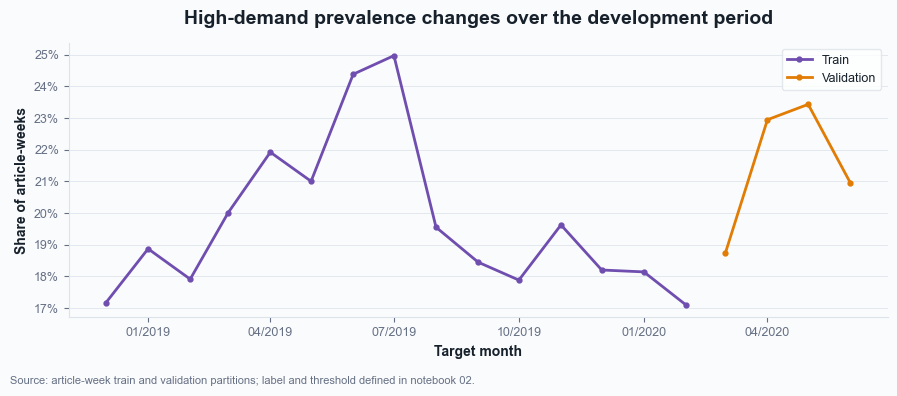

In [29]:
split_counts = model_data["split"].value_counts().rename_axis("partition").rename("rows")
prevalence_table = pd.DataFrame(
    {
        "rows": [len(train_all), len(validation_all)],
        "high_demand_prevalence": [train_all[TARGET].mean(), validation_all[TARGET].mean()],
        "first_target_week": [train_all["target_week"].min(), validation_all["target_week"].min()],
        "last_target_week": [train_all["target_week"].max(), validation_all["target_week"].max()],
    },
    index=["train", "validation"],
)
display(prevalence_table.assign(high_demand_prevalence=lambda table: table["high_demand_prevalence"].map("{:.1%}".format)))
display(split_counts.to_frame())
print(
    f"Definition from notebook 02: next-week recorded sales >= "
    f"{HIGH_DEMAND_THRESHOLD}; reference training quantile: "
    f"{classification_definition.get('training_quantile', 'not recorded')}."
)

development_data = pd.concat([train_all, validation_all], ignore_index=True)
development_data["month"] = development_data["target_week"].dt.to_period("M").dt.to_timestamp()
monthly_prevalence = (
    development_data.groupby(["month", "split"], observed=True)[TARGET]
    .mean()
    .unstack("split")
)
fig, axis = plt.subplots(figsize=(9, 4.2))
for partition, color in [("train", "#6F4EAF"), ("validation", "#E17C05")]:
    if partition in monthly_prevalence:
        axis.plot(
            monthly_prevalence.index,
            monthly_prevalence[partition],
            color=color,
            linewidth=2,
            marker="o",
            markersize=3.5,
            label=partition.capitalize(),
        )
axis.set_title("High-demand prevalence changes over the development period", fontsize=14, fontweight="bold", pad=14)
axis.set_xlabel("Target month", fontsize=10, fontweight="bold")
axis.set_ylabel("Share of article-weeks", fontsize=10, fontweight="bold")
axis.yaxis.set_major_formatter(plt.FuncFormatter(lambda value, _: f"{value:.0%}"))
axis.xaxis.set_major_formatter(mdates.DateFormatter("%m/%Y"))
axis.xaxis.set_major_locator(mdates.AutoDateLocator(minticks=5, maxticks=10))
axis.legend(frameon=True, facecolor="white", edgecolor=GRID, fancybox=True, fontsize=9)
style_axis(axis)
fig.tight_layout(rect=(0, 0.045, 1, 0.94))
add_source(fig, "Source: article-week train and validation partitions; label and threshold defined in notebook 02.")
plt.show()


## 2. Classification baselines

We use two reference points. The **training-prevalence baseline** assigns every validation row the positive-class prevalence observed in training; its class decision at 0.5 corresponds to the majority class. The **persistence-style baseline** predicts high demand when current-week sales already meet the same fixed unit threshold. Neither baseline learns from validation labels.


In [30]:
training_prevalence = float(y_train.mean())
baseline_probabilities = {
    "Training prevalence": np.full(len(y_validation), training_prevalence, dtype=float),
    "Current-sales rule": validation_sample["sales"].ge(HIGH_DEMAND_THRESHOLD).astype(float).to_numpy(),
}
baseline_results = []
for baseline_name, probabilities in baseline_probabilities.items():
    baseline_results.append(
        {"model": baseline_name, **classification_metrics(y_validation, probabilities)}
    )
baseline_metrics = pd.DataFrame(baseline_results).set_index("model")
display(baseline_metrics.round(3))
print(f"Train prevalence used by the baseline: {training_prevalence:.1%}")


,precision,recall,F1,PR-AUC,ROC-AUC,Brier
model,,,,,,
Training prevalence,0.000,0.000,0.0,0.213,0.500,0.168
Current-sales rule,0.786,0.814,0.8,0.679,0.877,0.087


Train prevalence used by the baseline: 19.9%


## 3. Preprocessing pipeline

Numerical predictors capture current and lagged sales, rolling demand, recent trend, prices, online-channel share, and cyclic week-of-year. Product type and broader product attributes are categorical. Identifiers, target values, split labels, and target-week fields are not predictors.

Imputation, scaling, and category encoding are fitted inside each model pipeline using training data only. Rare categories are grouped by the encoder and unseen validation categories are ignored safely. Sampling is stratified and reproducible; validation estimates represent the full validation partition shown above.


In [31]:
def make_feature_frame(frame):
    features = frame.loc[:, FEATURES].copy()
    for column in CATEGORICAL_FEATURES:
        features[column] = features[column].fillna("Unknown").astype(str)
    return features

X_train = make_feature_frame(training_sample)
X_validation = make_feature_frame(validation_sample)

numeric_pipeline = Pipeline(
    [
        ("imputer", SimpleImputer(strategy="median", add_indicator=True)),
        ("scaler", StandardScaler()),
    ]
)
categorical_pipeline = Pipeline(
    [
        ("imputer", SimpleImputer(strategy="constant", fill_value="Unknown")),
        (
            "onehot",
            OneHotEncoder(
                handle_unknown="ignore",
                min_frequency=25,
                max_categories=80,
                sparse_output=True,
            ),
        ),
    ]
)
preprocessor = ColumnTransformer(
    [
        ("numeric", numeric_pipeline, NUMERIC_FEATURES),
        ("categorical", categorical_pipeline, CATEGORICAL_FEATURES),
    ],
    remainder="drop",
    sparse_threshold=0.3,
)

for forbidden in {
    "article_id", "product_code", "target_next_week_sales", TARGET,
    "target_week", "split", "target_is_observed", "history_is_observed",
}:
    if forbidden in FEATURES:
        raise ValueError(f"Target leakage: {forbidden} appears among predictors.")

print(f"Numeric predictors: {len(NUMERIC_FEATURES)}")
print(f"Categorical predictors: {len(CATEGORICAL_FEATURES)}")
print(f"Rows used for fitting: {len(X_train):,}; validation: {len(X_validation):,}")


Numeric predictors: 18
Categorical predictors: 6
Rows used for fitting: 100,000; validation: 271,215


## 4. Candidate classifiers

We compare three distinct model families: regularized logistic regression, a shallow decision tree, and a Random Forest. Hyperparameters are deliberately moderate so the notebook remains usable on the full project dataset. All candidate pipelines share the same leakage-safe preprocessing and fixed random seed.


In [32]:
candidate_estimators = {
    "Logistic regression": LogisticRegression(
        C=1.0, solver="liblinear", max_iter=250, random_state=RANDOM_STATE
    ),
    "Decision tree": DecisionTreeClassifier(
        max_depth=10, min_samples_leaf=200, class_weight="balanced",
        random_state=RANDOM_STATE,
    ),
    "Random forest": RandomForestClassifier(
        n_estimators=60, max_depth=14, min_samples_leaf=200,
        max_features="sqrt", class_weight="balanced_subsample",
        n_jobs=-1, random_state=RANDOM_STATE,
    ),
}

model_pipelines = {}
validation_probabilities = {}
model_results = []
scored_validation = validation_sample[
    ["target_week", "section_name", "sales", TARGET]
].reset_index(drop=True).copy()
scored_validation["month"] = scored_validation["target_week"].dt.strftime("%Y-%m")

for model_name, estimator in candidate_estimators.items():
    pipeline = Pipeline(
        [("preprocessor", clone(preprocessor)), ("classifier", estimator)]
    )
    started = perf_counter()
    pipeline.fit(X_train, y_train)
    elapsed_seconds = perf_counter() - started
    probabilities = pipeline.predict_proba(X_validation)[:, 1]
    model_pipelines[model_name] = pipeline
    validation_probabilities[model_name] = probabilities
    model_results.append(
        {
            "model": model_name,
            "fit_seconds": elapsed_seconds,
            **classification_metrics(y_validation, probabilities, threshold=0.5),
        }
    )
    print(f"{model_name}: fit completed in {elapsed_seconds:.1f} s")


Logistic regression: fit completed in 4.1 s
Decision tree: fit completed in 5.4 s
Random forest: fit completed in 5.1 s


## 5. Chronological validation metrics

The primary comparison metric is **Average Precision (PR-AUC)** because it focuses on positive-class retrieval when prevalence is below 50%. Precision, recall, and F1 are reported at the conventional 0.5 probability threshold; ROC-AUC and Brier score provide complementary discrimination and probability-quality context. Accuracy is intentionally not used to choose the model.

Monthly validation metrics show whether performance is stable across the held-out chronological period. Small monthly groups can be noisy, so they are interpreted alongside the pooled validation result and their sample sizes.


,precision,recall,F1,PR-AUC,ROC-AUC,Brier,fit_seconds
model,,,,,,,
Logistic regression,0.850,0.728,0.784,0.873,0.955,0.064,4.071
Decision tree,0.680,0.896,0.773,0.872,0.955,0.081,5.440
Random forest,0.659,0.890,0.757,0.845,0.948,0.091,5.063
Current-sales rule,0.786,0.814,0.800,0.679,0.877,0.087,NaN
Training prevalence,0.000,0.000,0.000,0.213,0.500,0.168,NaN


Provisional selection by validation PR-AUC: Logistic regression


,model,month,n,PR-AUC,F1
0,Logistic regression,2020-03,92900,0.860,0.766
1,Logistic regression,2020-04,61921,0.866,0.788
2,Logistic regression,2020-05,73285,0.882,0.772
3,Logistic regression,2020-06,43109,0.911,0.832
4,Decision tree,2020-03,92900,0.854,0.751
5,Decision tree,2020-04,61921,0.859,0.759
6,Decision tree,2020-05,73285,0.884,0.800
7,Decision tree,2020-06,43109,0.916,0.792
8,Random forest,2020-03,92900,0.814,0.724
9,Random forest,2020-04,61921,0.822,0.747


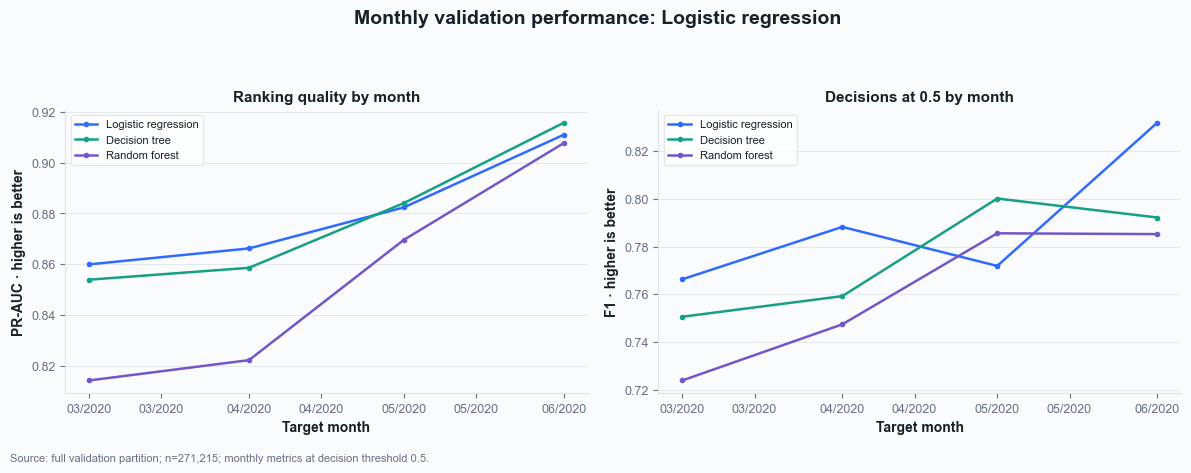

In [33]:
model_metrics = pd.DataFrame(model_results).set_index("model")
validation_metrics = pd.concat([baseline_metrics, model_metrics], axis=0)
validation_metrics = validation_metrics.sort_values("PR-AUC", ascending=False)
display(validation_metrics.round(3))

candidate_names = list(validation_probabilities)
selected_model = (
    validation_metrics.loc[candidate_names, "PR-AUC"]
    .sort_values(ascending=False)
    .index[0]
)
selected_probability = validation_probabilities[selected_model]
print(f"Provisional selection by validation PR-AUC: {selected_model}")

monthly_rows = []
for model_name, probabilities in validation_probabilities.items():
    for month, positions in scored_validation.groupby("month", sort=True).indices.items():
        positions = np.asarray(positions)
        month_metrics = classification_metrics(
            y_validation.iloc[positions],
            probabilities[positions],
            threshold=0.5,
        )
        monthly_rows.append(
            {
                "model": model_name,
                "month": month,
                "n": len(positions),
                "PR-AUC": month_metrics["PR-AUC"],
                "F1": month_metrics["F1"],
            }
        )
monthly_metrics = pd.DataFrame(monthly_rows)
display(monthly_metrics.head(12).round(3))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharex=True)
for model_name in candidate_names:
    subset = monthly_metrics.loc[monthly_metrics["model"].eq(model_name)].copy()
    dates = pd.to_datetime(subset["month"])
    color = MODEL_COLORS[model_name]
    axes[0].plot(dates, subset["PR-AUC"], marker="o", linewidth=1.8, markersize=3, color=color, label=model_name)
    axes[1].plot(dates, subset["F1"], marker="o", linewidth=1.8, markersize=3, color=color, label=model_name)
for axis in axes:
    axis.xaxis.set_major_formatter(mdates.DateFormatter("%m/%Y"))
    axis.xaxis.set_major_locator(mdates.AutoDateLocator(minticks=4, maxticks=8))
    axis.set_xlabel("Target month", fontsize=10, fontweight="bold")
    axis.legend(frameon=True, facecolor="white", edgecolor=GRID, fancybox=True, fontsize=8)
    style_axis(axis)
axes[0].set_title("Ranking quality by month", fontsize=11, fontweight="bold")
axes[0].set_ylabel("PR-AUC · higher is better", fontsize=10, fontweight="bold")
axes[1].set_title("Decisions at 0.5 by month", fontsize=11, fontweight="bold")
axes[1].set_ylabel("F1 · higher is better", fontsize=10, fontweight="bold")
fig.suptitle(f"Monthly validation performance: {selected_model}", fontsize=14, fontweight="bold", y=1.02)
fig.tight_layout(rect=(0, 0.045, 1, 0.94))
add_source(fig, f"Source: full validation partition; n={len(y_validation):,}; monthly metrics at decision threshold 0.5.")
plt.show()


## 6. Confusion matrix, ROC, Precision–Recall, and calibration

The following diagnostics use the provisionally selected model and the default probability threshold of 0.5. The precision–recall curve is foregrounded because the positive class is less prevalent; the ROC curve and calibration plot are complementary rather than standalone selection criteria.


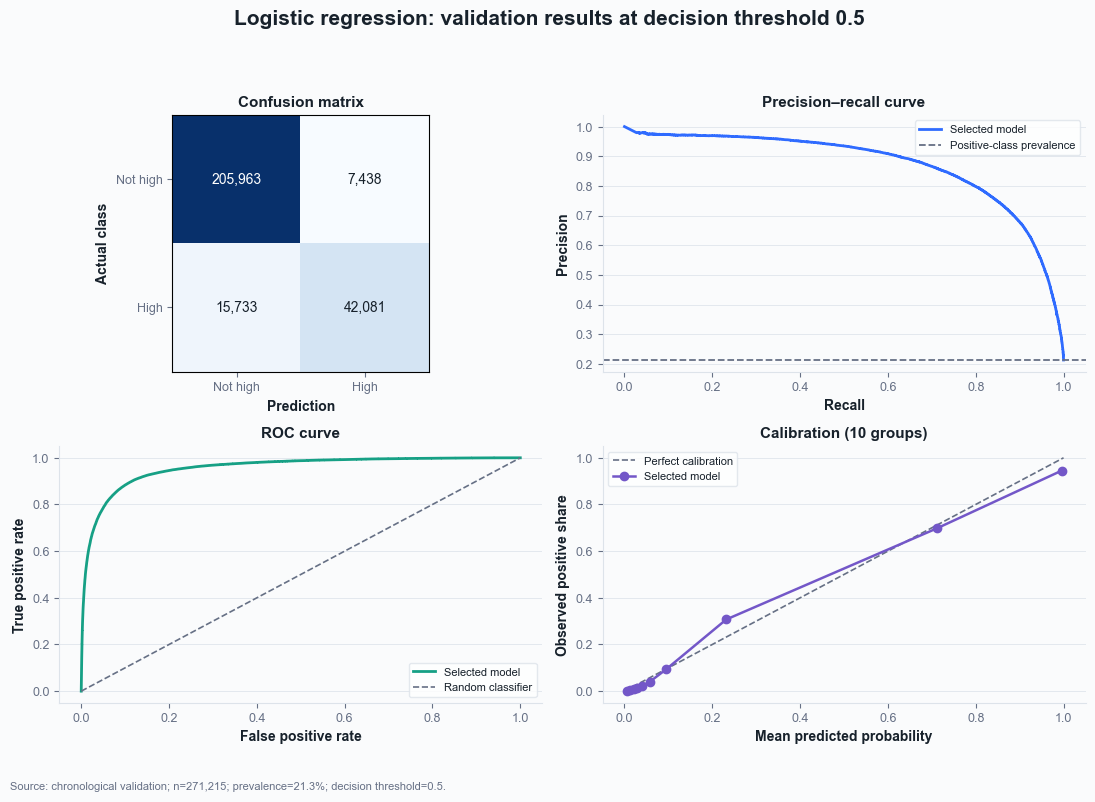

In [34]:
from sklearn.calibration import calibration_curve

default_prediction = (selected_probability >= 0.5).astype(int)
matrix = confusion_matrix(y_validation, default_prediction, labels=[0, 1])
precision_curve, recall_curve, _ = precision_recall_curve(y_validation, selected_probability)
false_positive_rate, true_positive_rate, _ = roc_curve(y_validation, selected_probability)
observed_fraction, mean_probability = calibration_curve(
    y_validation, selected_probability, n_bins=10, strategy="quantile"
)
validation_prevalence = float(y_validation.mean())

fig, axes = plt.subplots(2, 2, figsize=(11, 8))
fig.suptitle(
    f"{selected_model}: validation results at decision threshold 0.5",
    fontsize=15,
    fontweight="bold",
    y=0.99,
)

axis = axes[0, 0]
image = axis.imshow(matrix, cmap="Blues")
for row in range(2):
    for column in range(2):
        axis.text(column, row, f"{matrix[row, column]:,}", ha="center", va="center",
                  color="white" if (row, column) == (0, 0) else INK, fontsize=10)
axis.set_xticks([0, 1], ["Not high", "High"])
axis.set_yticks([0, 1], ["Not high", "High"])
axis.set_xlabel("Prediction", fontsize=10, fontweight="bold")
axis.set_ylabel("Actual class", fontsize=10, fontweight="bold")
axis.set_title("Confusion matrix", fontsize=11, fontweight="bold")

axis = axes[0, 1]
axis.plot(recall_curve, precision_curve, color=BLUE, linewidth=2, label="Selected model")
axis.axhline(validation_prevalence, color=MUTED, linestyle="--", linewidth=1.3, label="Positive-class prevalence")
axis.set_xlabel("Recall", fontsize=10, fontweight="bold")
axis.set_ylabel("Precision", fontsize=10, fontweight="bold")
axis.set_title("Precision–recall curve", fontsize=11, fontweight="bold")
axis.legend(frameon=True, facecolor="white", edgecolor=GRID, fancybox=True, fontsize=8)

axis = axes[1, 0]
axis.plot(false_positive_rate, true_positive_rate, color=TEAL, linewidth=2, label="Selected model")
axis.plot([0, 1], [0, 1], color=MUTED, linestyle="--", linewidth=1.2, label="Random classifier")
axis.set_xlabel("False positive rate", fontsize=10, fontweight="bold")
axis.set_ylabel("True positive rate", fontsize=10, fontweight="bold")
axis.set_title("ROC curve", fontsize=11, fontweight="bold")
axis.legend(frameon=True, facecolor="white", edgecolor=GRID, fancybox=True, fontsize=8)

axis = axes[1, 1]
axis.plot([0, 1], [0, 1], color=MUTED, linestyle="--", linewidth=1.2, label="Perfect calibration")
axis.plot(mean_probability, observed_fraction, color=VIOLET, marker="o", linewidth=1.8, label="Selected model")
axis.set_xlabel("Mean predicted probability", fontsize=10, fontweight="bold")
axis.set_ylabel("Observed positive share", fontsize=10, fontweight="bold")
axis.set_title("Calibration (10 groups)", fontsize=11, fontweight="bold")
axis.legend(frameon=True, facecolor="white", edgecolor=GRID, fancybox=True, fontsize=8)

for axis in axes.flat:
    if axis is not axes[0, 0]:
        style_axis(axis)  # A grid would cross the confusion-matrix counts.
fig.tight_layout(rect=(0, 0.055, 1, 0.94))
add_source(
    fig,
    f"Source: chronological validation; n={len(y_validation):,}; prevalence={validation_prevalence:.1%}; decision threshold=0.5.",
)
plt.show()


## 7. Decision-threshold and business-error analysis

The probability decision threshold is separate from the fixed sales-unit threshold that defines high demand. We sweep decision thresholds on validation and choose the one with the highest validation F1; ties are resolved by higher precision and then the higher threshold. This is a transparent comparison rule, not a business-optimal policy: real inventory costs, margins, stock-outs, and replenishment constraints are unavailable here.

A false positive flags an article for high demand that does not meet the target definition; a false negative misses an article that does. Their operational costs can differ, so the threshold must be revisited when those costs are known.


,precision,recall,F1,Brier
Decision threshold 0.5,0.850,0.728,0.784,0.064
F1-optimal on validation (0.30),0.783,0.818,0.800,0.064


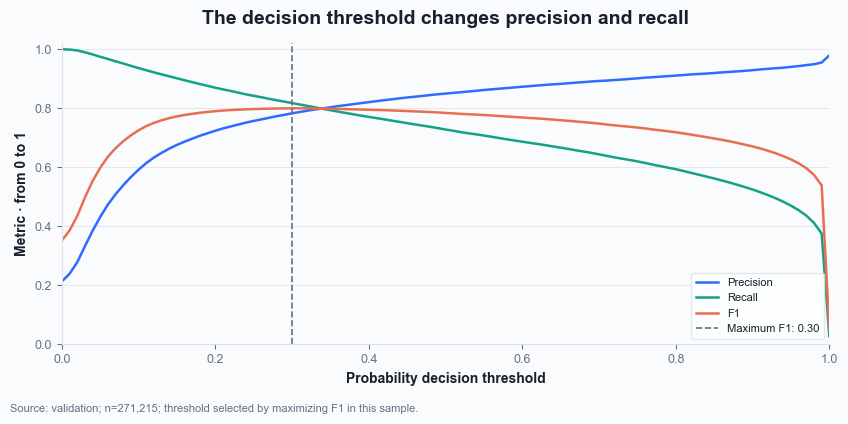

,count,interpretation
True negative,200299,"Not high demand, correctly predicted"
False positive,13102,High-demand alert without an observed positive
False negative,10544,High demand missed
True positive,47270,High demand detected


,n,positives,false_positives,actual_negatives,false_negatives,actual_positives,false_positive_rate,false_negative_rate
section_name,,,,,,,,
Womens Everyday Collection,29942,8617,1673,21325,1226,8617,0.078,0.142
Divided Collection,28197,7053,2090,21144,1266,7053,0.099,0.179
Womens Lingerie,14274,5675,1063,8599,748,5675,0.124,0.132
Womens Tailoring,13763,4354,886,9409,661,4354,0.094,0.152
"Womens Swimwear, beachwear",11700,5148,443,6552,509,5148,0.068,0.099
Womens Casual,9888,2923,534,6965,491,2923,0.077,0.168
Womens Small accessories,9370,1345,521,8025,448,1345,0.065,0.333
Womens Trend,8811,1155,343,7656,405,1155,0.045,0.351
Mama,7814,562,121,7252,256,562,0.017,0.456


Section-level rates describe errors in the full validation partition; they do not imply that the category causes the error.


In [35]:
threshold_rows = []
for decision_threshold in np.linspace(0, 1, 101):
    threshold_metrics = classification_metrics(
        y_validation,
        selected_probability,
        threshold=float(decision_threshold),
    )
    threshold_rows.append({"threshold": decision_threshold, **threshold_metrics})
threshold_sweep = pd.DataFrame(threshold_rows)
best_f1 = threshold_sweep["F1"].max()
best_candidates = threshold_sweep.loc[np.isclose(threshold_sweep["F1"], best_f1)]
best_threshold = float(
    best_candidates.sort_values(["precision", "threshold"], ascending=[False, False])
    .iloc[0]["threshold"]
)
best_threshold_metrics = classification_metrics(
    y_validation, selected_probability, threshold=best_threshold
)
default_threshold_metrics = classification_metrics(
    y_validation, selected_probability, threshold=0.5
)
threshold_comparison = pd.DataFrame(
    [default_threshold_metrics, best_threshold_metrics],
    index=["Decision threshold 0.5", f"F1-optimal on validation ({best_threshold:.2f})"],
)
display(threshold_comparison[["precision", "recall", "F1", "Brier"]].round(3))

fig, axis = plt.subplots(figsize=(8.5, 4.5))
for metric, color in [("precision", BLUE), ("recall", TEAL), ("F1", CORAL)]:
    axis.plot(threshold_sweep["threshold"], threshold_sweep[metric], color=color, linewidth=1.8, label=metric.capitalize())
axis.axvline(best_threshold, color=MUTED, linestyle="--", linewidth=1.2, label=f"Maximum F1: {best_threshold:.2f}")
axis.set_xlabel("Probability decision threshold", fontsize=10, fontweight="bold")
axis.set_ylabel("Metric · from 0 to 1", fontsize=10, fontweight="bold")
axis.set_title("The decision threshold changes precision and recall", fontsize=14, fontweight="bold", pad=14)
axis.set_xlim(0, 1)
axis.set_ylim(0, 1.02)
axis.legend(frameon=True, facecolor="white", edgecolor=GRID, fancybox=True, fontsize=8)
style_axis(axis)
fig.tight_layout(rect=(0, 0.045, 1, 0.94))
add_source(fig, f"Source: validation; n={len(y_validation):,}; threshold selected by maximizing F1 in this sample.")
plt.show()

prediction_at_best = (selected_probability >= best_threshold).astype(int)
tn, fp, fn, tp = confusion_matrix(y_validation, prediction_at_best, labels=[0, 1]).ravel()
error_summary = pd.DataFrame(
    {
        "count": [tn, fp, fn, tp],
        "interpretation": [
            "Not high demand, correctly predicted",
            "High-demand alert without an observed positive",
            "High demand missed",
            "High demand detected",
        ],
    },
    index=["True negative", "False positive", "False negative", "True positive"],
)
display(error_summary)

segment_errors = scored_validation[["section_name", TARGET]].copy()
segment_errors["prediction"] = prediction_at_best
segment_errors["false_positive"] = (
    segment_errors["prediction"].eq(1) & segment_errors[TARGET].eq(0)
).astype(int)
segment_errors["actual_negative"] = segment_errors[TARGET].eq(0).astype(int)
segment_errors["false_negative"] = (
    segment_errors["prediction"].eq(0) & segment_errors[TARGET].eq(1)
).astype(int)
segment_errors["actual_positive"] = segment_errors[TARGET].eq(1).astype(int)
segment_summary = (
    segment_errors.groupby("section_name", dropna=False)
    .agg(
        n=(TARGET, "size"),
        positives=(TARGET, "sum"),
        false_positives=("false_positive", "sum"),
        actual_negatives=("actual_negative", "sum"),
        false_negatives=("false_negative", "sum"),
        actual_positives=("actual_positive", "sum"),
    )
)
segment_summary["false_positive_rate"] = (
    segment_summary["false_positives"] / segment_summary["actual_negatives"].replace(0, np.nan)
)
segment_summary["false_negative_rate"] = (
    segment_summary["false_negatives"] / segment_summary["actual_positives"].replace(0, np.nan)
)
display(segment_summary.sort_values("n", ascending=False).head(12).round(3))
print(
    "Section-level rates describe errors in the full validation partition; "
    "they do not imply that the category causes the error."
)


## 8. Model selection and limitations

The candidate is selected by the highest pooled PR-AUC on the full chronological validation partition; its probability threshold is selected separately by validation F1. Neither choice uses the final test partition. After the feature set, model, and decision policy are frozen, the project may perform a single independent test evaluation in a later, explicitly controlled step.

### Interpretation and limitations

- The label represents **recorded sales**, not latent demand; stock availability and unmet demand are not observed.
- The candidate population includes articles sold in the current week, so results do not directly cover new or inactive articles.
- Training is a capped, stratified sample for iteration; validation uses every published validation row. Small segment and monthly groups can have unstable metrics.
- The threshold optimizes F1, not inventory profit or service level. False-positive and false-negative costs are not available.
- Calibration and performance may drift across weeks and product groups; monthly and section-level results are descriptive.
- Product associations are predictive, not causal. No final-test result is reported here.

Re-run from the first cell after changing the current data publication or model setup. Record the run identifier, sample limits, random seed, predictors, hyperparameters, and validation metrics when comparing experiments.


In [36]:
selection_summary = pd.Series(
    {
        "selected_model": selected_model,
        "selection_metric": "PR-AUC on chronological validation",
        "validation_PR_AUC": classification_metrics(
            y_validation, selected_probability
        )["PR-AUC"],
        "validation_F1_at_0.5": default_threshold_metrics["F1"],
        "decision_threshold_selected_on_validation": best_threshold,
        "validation_F1_at_selected_threshold": best_threshold_metrics["F1"],
        "validation_sample_rows": len(y_validation),
        "train_sample_rows": len(y_train),
        "high_demand_sales_threshold": HIGH_DEMAND_THRESHOLD,
        "final_test_used": False,
    },
    name="value",
)
display(selection_summary.to_frame())
display(validation_metrics.round(3))


,value
selected_model,Logistic regression
selection_metric,PR-AUC on chronological validation
validation_PR_AUC,0.872541
validation_F1_at_0.5,0.78412
decision_threshold_selected_on_validation,0.3
validation_F1_at_selected_threshold,0.799926
validation_sample_rows,271215
train_sample_rows,100000
high_demand_sales_threshold,16
final_test_used,False


,precision,recall,F1,PR-AUC,ROC-AUC,Brier,fit_seconds
model,,,,,,,
Logistic regression,0.850,0.728,0.784,0.873,0.955,0.064,4.071
Decision tree,0.680,0.896,0.773,0.872,0.955,0.081,5.440
Random forest,0.659,0.890,0.757,0.845,0.948,0.091,5.063
Current-sales rule,0.786,0.814,0.800,0.679,0.877,0.087,NaN
Training prevalence,0.000,0.000,0.000,0.213,0.500,0.168,NaN
